In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [22]:
students = pd.read_csv("students.csv")

In [23]:
print(students.shape)
print(students.isnull().sum())
students.describe

(100, 2)
hours_studied    0
exam_score       0
dtype: int64


<bound method NDFrame.describe of     hours_studied  exam_score
0             4.4        56.7
1             9.6        85.8
2             7.6        76.0
3             6.4        58.4
4             2.4        43.3
..            ...         ...
95            5.4        58.6
96            5.7        63.8
97            4.8        60.8
98            1.2        38.8
99            2.0        46.0

[100 rows x 2 columns]>

In [24]:
students

,hours_studied,exam_score
0,4.4,56.7
1,9.6,85.8
2,7.6,76.0
3,6.4,58.4
4,2.4,43.3
...,...,...
95,5.4,58.6
96,5.7,63.8
97,4.8,60.8
98,1.2,38.8


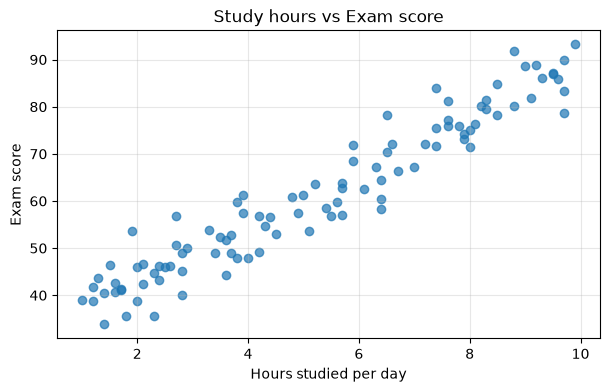

In [25]:
plt.figure(figsize=(7,4))
plt.scatter(students["hours_studied"], students["exam_score"], alpha=0.7)
plt.xlabel("Hours studied per day")
plt.ylabel("Exam score")
plt.title("Study hours vs Exam score")
plt.grid(alpha=0.3)
plt.show()


In [26]:
X = students[["hours_studied"]]
Y = students["exam_score"]

print("X shape", X.shape)
print("Y shape", Y.shape)

X shape (100, 1)
Y shape (100,)


In [27]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X,Y, test_size=0.2, random_state=42
)

In [28]:
model = LinearRegression()
model.fit(X_train, Y_train) #this is the learning step

print("Intercept: ", round(model.intercept_, 2))
print("Coefficient: ", round(model.coef_[0], 2))


Intercept:  30.99
Coefficient:  5.77


In [29]:
Y_pred = model.predict(X_test)
results = pd.DataFrame({
    "Hours": X_test["hours_studied"].values,
    "Actual score": Y_test.values,
    "Predicted score": Y_pred.round(1),
})
results["Difference"] = (results["Actual score"] - results["Predicted score"]).round(1)
results.head(10)

,Hours,Actual score,Predicted score,Difference
0,1.6,42.7,40.2,2.5
1,9.1,81.8,83.5,-1.7
2,8.0,71.5,77.1,-5.6
3,7.0,67.2,71.4,-4.2
4,3.3,53.9,50.0,3.9
5,5.0,61.3,59.8,1.5
6,3.6,51.8,51.8,0.0
7,8.8,91.9,81.7,10.2
8,1.2,41.7,37.9,3.8
9,4.4,56.7,56.4,0.3


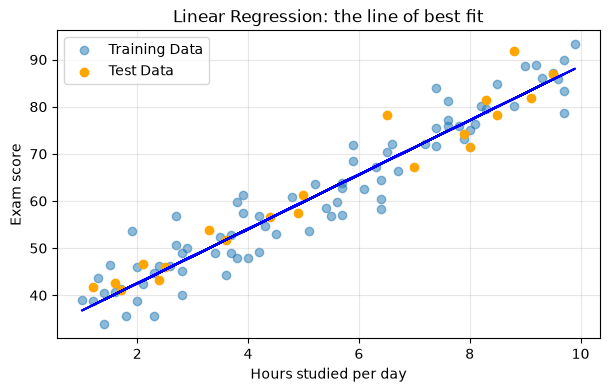

In [30]:
plt.figure(figsize=(7,4))
plt.scatter(X_train, Y_train, alpha=0.5, label= "Training Data")
plt.scatter(X_test, Y_test, color="orange", label= "Test Data")

plt.plot(X_train, model.predict(X_train), color="blue")
plt.xlabel("Hours studied per day")
plt.ylabel("Exam score")
plt.title("Linear Regression: the line of best fit")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [31]:
new_student = pd.DataFrame({"hours_studied": [6.5]})
predicted = model.predict(new_student)
print(f"a student who studied 6.5 hours is expected to score about {predicted[0]:.1f}")

a student who studied 6.5 hours is expected to score about 68.5
